In [1]:
from pathlib import Path
import json
import random
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 128
MAX_EPOCHS = 35
PATIENCE = 7
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
NUM_CLASSES = 5

CLASS_NAMES = [
    "N - Normal",
    "S - Supraventricular",
    "V - Ventricular",
    "F - Fusion",
    "Q - Unknown/Other"
]

# Tự xác định thư mục dự án
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "ECG" / "processed"
MODEL_DIR = PROJECT_ROOT / "models" / "ECG"
RESULT_DIR = PROJECT_ROOT / "results" / "ECG"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
(RESULT_DIR / "confusion_matrix").mkdir(parents=True, exist_ok=True)
(RESULT_DIR / "training_history").mkdir(parents=True, exist_ok=True)

DATA_FILE = PROCESSED_DIR / "mitbih_processed.npz"

print("Project:", PROJECT_ROOT)
print("Device:", DEVICE)
print("Dataset exists:", DATA_FILE.exists())
print("Model directory:", MODEL_DIR)
print("Results directory:", RESULT_DIR)

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Không tìm thấy: {DATA_FILE}")

Project: d:\projects\nasa-challenge
Device: cpu
Dataset exists: True
Model directory: d:\projects\nasa-challenge\models\ECG
Results directory: d:\projects\nasa-challenge\results\ECG


In [2]:
# Load dữ liệu ECG
data = np.load(DATA_FILE)

X_train = data["X_train"].astype(np.float32)
y_train = data["y_train"].astype(np.int64)

X_val = data["X_val"].astype(np.float32)
y_val = data["y_val"].astype(np.int64)

X_test = data["X_test"].astype(np.float32)
y_test = data["y_test"].astype(np.int64)

class_weights_np = data["class_weights"].astype(np.float32)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)
print("Class weights:", class_weights_np)

assert X_train.shape[1] == 187
assert X_val.shape[1] == 187
assert X_test.shape[1] == 187

assert set(np.unique(y_train)) == set(range(5))

Train: (70043, 187)
Validation: (17511, 187)
Test: (21892, 187)
Class weights: [ 0.2416234  7.878853   3.0256155 27.307213   2.72276  ]


Tạo DataLoader
CNN 1D yêu cầu dữ liệu có dạng (batch, channel, sequence_length).

Dữ liệu hiện tại có 187 điểm tín hiệu nên ta chuyển thành (N, 1, 187).

In [3]:
X_train_t = torch.from_numpy(X_train).unsqueeze(1)
X_val_t = torch.from_numpy(X_val).unsqueeze(1)
X_test_t = torch.from_numpy(X_test).unsqueeze(1)

y_train_t = torch.from_numpy(y_train)
y_val_t = torch.from_numpy(y_val)
y_test_t = torch.from_numpy(y_test)

train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    TensorDataset(X_val_t, y_val_t),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    TensorDataset(X_test_t, y_test_t),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 548
Validation batches: 137
Test batches: 172


Xây dựng mô hình 1D-CNN
Kiến trúc mô hình
Input: 1 × 187

Conv1D: 1 → 32

Conv1D: 32 → 64

Conv1D: 64 → 128

Global Average Pooling

Output: 5 lớp ECG

In [4]:
class ECG1DCNN(nn.Module):

    def __init__(self, num_classes=5):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv1d(1, 32, kernel_size=7, padding=3, bias=False),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=5, padding=2, bias=False),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm1d(128),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.35),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = ECG1DCNN(NUM_CLASSES).to(DEVICE)

print(model)

print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

ECG1DCNN(
  (features): Sequential(
    (0): Conv1d(1, 32, kernel_size=(7,), stride=(1,), padding=(3,), bias=False)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,), bias=False)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,), bias=False)
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.35, inplace=False)
    (2): Linear(in_features=128, out_features=

Loss, Optimizer và Metrics
Loss: Weighted Cross Entropy.

Lý do: dữ liệu bị mất cân bằng nghiêm trọng. Lớp Normal chiếm 82,77%, trong khi lớp Fusion chỉ chiếm 0,73%.

In [5]:
class_weights_t = torch.tensor(
    class_weights_np,
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights_t
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)


def calculate_metrics(y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=list(range(NUM_CLASSES)),
            zero_division=0
        )
    )

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES))
    )

    specificity = []

    for i in range(NUM_CLASSES):

        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = cm.sum() - tp - fn - fp

        spec = tn / (tn + fp) if (tn + fp) > 0 else 0

        specificity.append(spec)

    return {
        "accuracy": accuracy,
        "macro_precision": np.mean(precision),
        "macro_recall": np.mean(recall),
        "macro_f1": np.mean(f1),

        "per_class_precision": precision,
        "per_class_recall": recall,
        "per_class_f1": f1,
        "per_class_specificity": np.array(specificity),

        "support": support,
        "confusion_matrix": cm
    }

In [ ]:
# Hàm Train và Validation
def run_epoch(loader, training=True):

    model.train(training)

    total_loss = 0

    all_true = []
    all_pred = []

    context = torch.enable_grad() if training else torch.no_grad()

    with context:

        for xb, yb in loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(xb)

            loss = criterion(logits, yb)

            if training:

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=5.0
                )

                optimizer.step()

            total_loss += loss.item() * xb.size(0)

            predictions = torch.argmax(logits, dim=1)

            all_true.extend(yb.cpu().numpy())
            all_pred.extend(predictions.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)

    metrics = calculate_metrics(
        np.array(all_true),
        np.array(all_pred)
    )

    return avg_loss, metrics

Huấn luyện và lưu checkpoint
Checkpoint tốt nhất được chọn theo Validation Macro-F1, không dựa trên Test.

In [7]:
history = []

best_val_f1 = -1
best_epoch = 0
epochs_without_improvement = 0

best_path = MODEL_DIR / "best_model.pth"
last_path = MODEL_DIR / "last_checkpoint.pth"

for epoch in range(1, MAX_EPOCHS + 1):

    train_loss, train_metrics = run_epoch(
        train_loader,
        training=True
    )

    val_loss, val_metrics = run_epoch(
        val_loader,
        training=False
    )

    scheduler.step(val_metrics["macro_f1"])

    current_lr = optimizer.param_groups[0]["lr"]

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_loss,
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "learning_rate": current_lr
    }

    history.append(row)

    improved = val_metrics["macro_f1"] > best_val_f1

    if improved:

        best_val_f1 = val_metrics["macro_f1"]
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_macro_f1": best_val_f1,
            "class_names": CLASS_NAMES
        }, best_path)

    else:
        epochs_without_improvement += 1

    # Luôn lưu checkpoint mới nhất
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_macro_f1": best_val_f1,
        "history": history
    }, last_path)

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train F1: {train_metrics['macro_f1']:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val F1: {val_metrics['macro_f1']:.4f} | "
        f"Val Acc: {val_metrics['accuracy']:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    if epochs_without_improvement >= PATIENCE:

        print("Early stopping!")
        print("Best epoch:", best_epoch)

        break


history_df = pd.DataFrame(history)

history_df.to_csv(
    RESULT_DIR / "training_history" / "training_history.csv",
    index=False
)

print("\nBest epoch:", best_epoch)
print("Best validation Macro-F1:", best_val_f1)
print("Best checkpoint:", best_path)

Epoch 01/35 | Train Loss: 0.7629 | Train F1: 0.4614 | Val Loss: 0.4569 | Val F1: 0.6353 | Val Acc: 0.8315 | LR: 0.001000
Epoch 02/35 | Train Loss: 0.4927 | Train F1: 0.5763 | Val Loss: 0.4180 | Val F1: 0.6184 | Val Acc: 0.7992 | LR: 0.001000
Epoch 03/35 | Train Loss: 0.4225 | Train F1: 0.6105 | Val Loss: 0.3988 | Val F1: 0.6110 | Val Acc: 0.7414 | LR: 0.001000
Epoch 04/35 | Train Loss: 0.3949 | Train F1: 0.6344 | Val Loss: 0.3333 | Val F1: 0.6261 | Val Acc: 0.8012 | LR: 0.000500
Epoch 05/35 | Train Loss: 0.3504 | Train F1: 0.6648 | Val Loss: 0.3098 | Val F1: 0.8035 | Val Acc: 0.9453 | LR: 0.000500
Epoch 06/35 | Train Loss: 0.3214 | Train F1: 0.6684 | Val Loss: 0.2927 | Val F1: 0.6907 | Val Acc: 0.8894 | LR: 0.000500
Epoch 07/35 | Train Loss: 0.3131 | Train F1: 0.6779 | Val Loss: 0.2980 | Val F1: 0.6785 | Val Acc: 0.8756 | LR: 0.000500
Epoch 08/35 | Train Loss: 0.3016 | Train F1: 0.6831 | Val Loss: 0.2738 | Val F1: 0.6418 | Val Acc: 0.8201 | LR: 0.000250
Epoch 09/35 | Train Loss: 0.2708

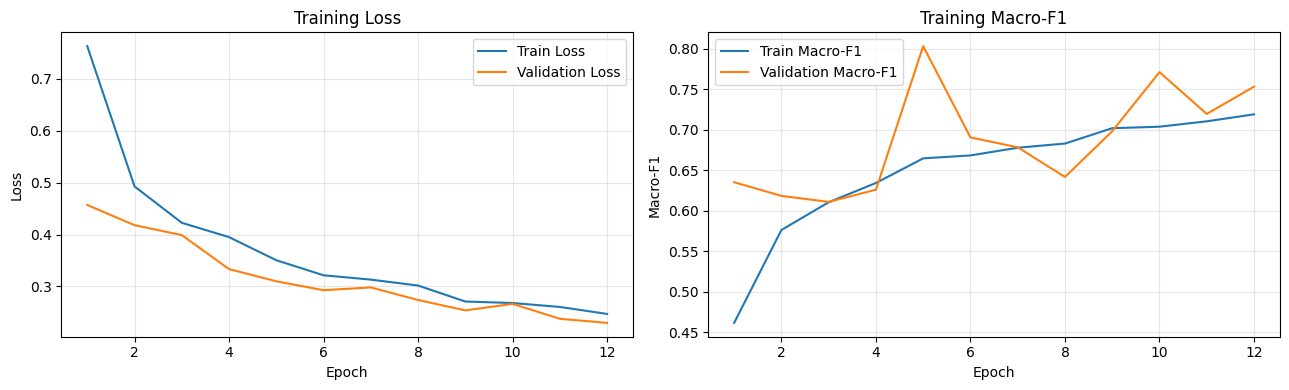

In [ ]:
# Biểu đồ quá trình huấn luyện
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Loss
axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train Loss"
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)


# Macro F1
axes[1].plot(
    history_df["epoch"],
    history_df["train_macro_f1"],
    label="Train Macro-F1"
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    label="Validation Macro-F1"
)

axes[1].set_title("Training Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "training_history" / "training_curves.png",
    dpi=160
)

plt.show()

Đánh giá trên Test chính thức
Chỉ chạy cell này sau khi đã hoàn thành huấn luyện và chọn checkpoint.

In [9]:
checkpoint = torch.load(
    best_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

test_loss, _ = run_epoch(
    test_loader,
    training=False
)

test_true = []
test_pred = []

with torch.no_grad():

    for xb, yb in test_loader:

        xb = xb.to(DEVICE)

        logits = model(xb)

        predictions = torch.argmax(
            logits,
            dim=1
        )

        test_pred.extend(predictions.cpu().numpy())
        test_true.extend(yb.numpy())


test_true = np.array(test_true)
test_pred = np.array(test_pred)

test_metrics = calculate_metrics(
    test_true,
    test_pred
)

print("========== ECG TEST RESULTS ==========")

print("Best epoch:", checkpoint["epoch"])

print("Test Loss:", round(test_loss, 4))

print("Accuracy:",
      round(test_metrics["accuracy"], 4))

print("Macro Precision:",
      round(test_metrics["macro_precision"], 4))

print("Macro Recall:",
      round(test_metrics["macro_recall"], 4))

print("Macro F1:",
      round(test_metrics["macro_f1"], 4))

print("\nClassification Report:")

print(
    classification_report(
        test_true,
        test_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

========== ECG TEST RESULTS ==========
Best epoch: 5
Test Loss: 0.2391
Accuracy: 0.9412
Macro Precision: 0.7407
Macro Recall: 0.8675
Macro F1: 0.7918

Classification Report:
                      precision    recall  f1-score   support

          N - Normal       0.98      0.95      0.97     18118
S - Supraventricular       0.44      0.65      0.53       556
     V - Ventricular       0.82      0.91      0.86      1448
          F - Fusion       0.53      0.85      0.65       162
   Q - Unknown/Other       0.94      0.97      0.95      1608

            accuracy                           0.94     21892
           macro avg       0.74      0.87      0.79     21892
        weighted avg       0.95      0.94      0.95     21892



,class,precision,recall_sensitivity,specificity,f1,support
0,N - Normal,0.982929,0.950215,0.920774,0.966295,18118
1,S - Supraventricular,0.439083,0.654676,0.978206,0.525632,556
2,V - Ventricular,0.819083,0.912983,0.985717,0.863488,1448
3,F - Fusion,0.526923,0.845679,0.994340,0.649289,162
4,Q - Unknown/Other,0.935484,0.973881,0.994676,0.954296,1608


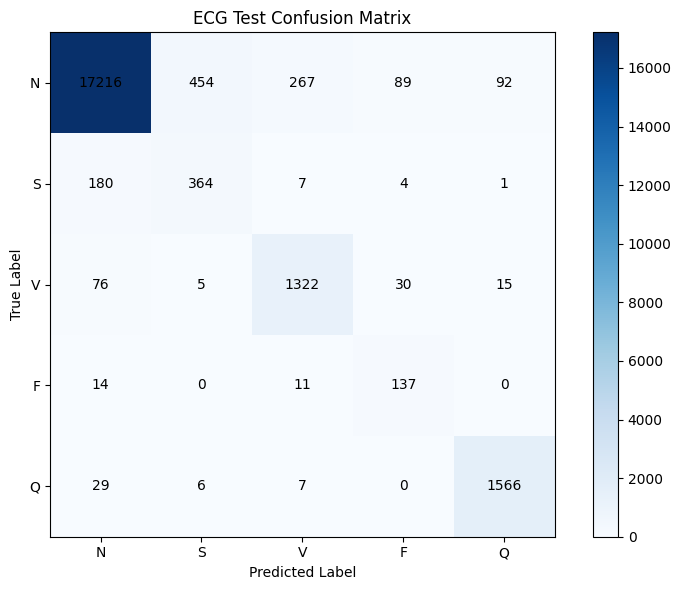

Đã lưu kết quả tại: d:\projects\nasa-challenge\results\ECG


In [10]:
# Lưu báo cáo và Confusion Matrix
cm = test_metrics["confusion_matrix"]

metrics_df = pd.DataFrame({

    "class": CLASS_NAMES,

    "precision": test_metrics["per_class_precision"],

    "recall_sensitivity": test_metrics["per_class_recall"],

    "specificity": test_metrics["per_class_specificity"],

    "f1": test_metrics["per_class_f1"],

    "support": test_metrics["support"]
})

display(metrics_df)

metrics_df.to_csv(
    RESULT_DIR / "metrics_per_class.csv",
    index=False
)


summary = {

    "dataset": "MIT-BIH ECG Heartbeat",

    "model": "ECG1DCNN",

    "best_epoch": int(checkpoint["epoch"]),

    "test_loss": float(test_loss),

    "accuracy": float(test_metrics["accuracy"]),

    "macro_precision": float(test_metrics["macro_precision"]),

    "macro_recall": float(test_metrics["macro_recall"]),

    "macro_f1": float(test_metrics["macro_f1"]),

    "note": "Beat-level random split; patient-independent generalization is not established."
}

pd.DataFrame([summary]).to_csv(
    RESULT_DIR / "metrics_summary.csv",
    index=False
)

with open(
    RESULT_DIR / "metrics_summary.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        ensure_ascii=False,
        indent=2
    )


# Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(cm, cmap="Blues")

ax.set_title("ECG Test Confusion Matrix")

ax.set_xlabel("Predicted Label")

ax.set_ylabel("True Label")

ax.set_xticks(range(NUM_CLASSES))
ax.set_xticklabels(["N", "S", "V", "F", "Q"])

ax.set_yticks(range(NUM_CLASSES))
ax.set_yticklabels(["N", "S", "V", "F", "Q"])

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):

        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

fig.colorbar(im, ax=ax)

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "confusion_matrix" / "confusion_matrix_test.png",
    dpi=160
)

plt.show()

print("Đã lưu kết quả tại:", RESULT_DIR)